# GeoSense – Exploratory Data Analysis
**Author:** Seif Omara · Data cleaning & EDA

Goal: understand the data **before** modelling, and turn what we see into concrete decisions for the team
(which countries to keep, how to resize, what to mask, how to handle imbalance, what could fool the model).

Inputs: `data/manifest.csv` (the shared split) and `data/image_stats.csv` (per-image size and colour statistics
computed by `geosense.clean`). Some sections also read images from the Kaggle folder.

In [1]:
import os, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# ---- set this to where you unzipped the Kaggle dataset ----
DATA_ROOT = Path(os.environ.get("GEOSENSE_DATA", "~/Downloads/compressed_dataset")).expanduser()
REPO = Path.cwd().parent                     # notebook lives in notebooks/
RESULTS = REPO / "results"; RESULTS.mkdir(exist_ok=True)

manifest = pd.read_csv(REPO / "data" / "manifest.csv")
stats = pd.read_csv(REPO / "data" / "image_stats.csv")      # all 49,997 raw images
report = json.load(open(REPO / "data" / "cleaning_report.json"))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(42)

def save(fig, name):
    fig.savefig(RESULTS / name, dpi=150, bbox_inches="tight")
print(DATA_ROOT, DATA_ROOT.exists())

/Users/seif/Downloads/compressed_dataset True


## 1. The dataset at a glance

In [2]:
overview = pd.Series({
    "raw images": len(stats),
    "raw countries": stats.country.nunique(),
    "image size (px)": ", ".join(f"{w}x{h}" for w, h in stats.groupby(["width", "height"]).size().index),
    "total size (GB)": round(stats.bytes.sum() / 1e9, 2),
    "median file size (KB)": round(stats.bytes.median() / 1e3),
    "images after cleaning": len(manifest),
    "countries after cleaning": manifest.country.nunique(),
})
overview.to_frame("value")

,value
raw images,49997
raw countries,124
image size (px),"1030x703, 1536x662"
total size (GB),7.18
median file size (KB),139
images after cleaning,47990
countries after cleaning,56


Every image has the **same size, 1536×662**. That's good, because there's no messy mix of resolutions. But the aspect
ratio is **2.3 : 1**, a wide panorama, while the models expect a square 224×224 input (see section 3).

## 2. Class imbalance

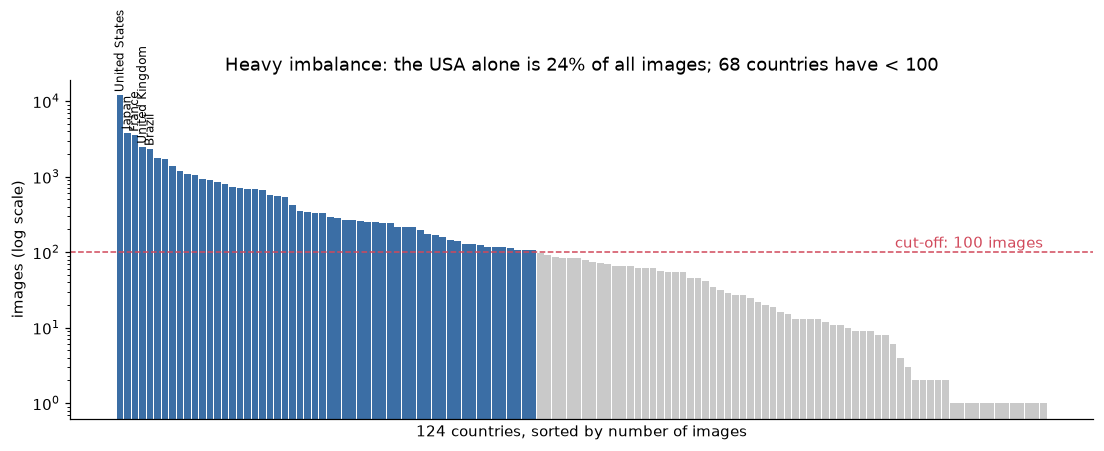

In [3]:
raw_counts = stats.country.value_counts()
fig, ax = plt.subplots(figsize=(12, 4))
colors = np.where(raw_counts.values >= 100, "#3b6ea5", "#c9c9c9")
ax.bar(range(len(raw_counts)), raw_counts.values, color=colors, width=0.9)
ax.set_yscale("log"); ax.axhline(100, color="#d1495b", lw=1, ls="--")
ax.text(len(raw_counts) - 1, 115, "cut-off: 100 images", ha="right", color="#d1495b")
for i in range(5):
    ax.text(i, raw_counts.values[i] * 1.1, raw_counts.index[i], rotation=90, ha="center", va="bottom", fontsize=8)
ax.set_xticks([]); ax.set_xlabel("124 countries, sorted by number of images")
ax.set_ylabel("images (log scale)")
ax.set_title(f"Heavy imbalance: the USA alone is {raw_counts.iloc[0] / raw_counts.sum():.0%} of all images; "
             f"{(raw_counts < 100).sum()} countries have < 100")
save(fig, "01_class_distribution.png"); plt.show()

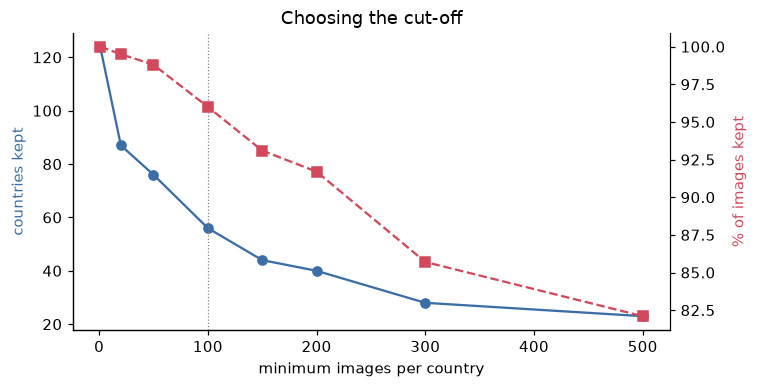

,min_images,n_classes,pct_images_kept
0,1,124,100.0
1,20,87,99.5
2,50,76,98.8
3,100,56,96.0
4,150,44,93.1
5,200,40,91.7
6,300,28,85.7
7,500,23,82.1


In [4]:
thr = pd.DataFrame(report["threshold_table"])
fig, ax1 = plt.subplots(figsize=(7, 3.5))
ax1.plot(thr.min_images, thr.n_classes, "o-", color="#3b6ea5"); ax1.set_ylabel("countries kept", color="#3b6ea5")
ax2 = ax1.twinx(); ax2.plot(thr.min_images, thr.pct_images_kept, "s--", color="#d1495b")
ax2.set_ylabel("% of images kept", color="#d1495b"); ax2.spines["right"].set_visible(True)
ax1.axvline(100, color="grey", lw=0.8, ls=":")
ax1.set_xlabel("minimum images per country"); ax1.set_title("Choosing the cut-off")
save(fig, "02_cutoff_tradeoff.png"); plt.show()
thr

In [5]:
kept = manifest.country.value_counts()
print(f"After cleaning: {len(kept)} countries. Largest/smallest = {kept.iloc[0]} / {kept.iloc[-1]} "
      f"({kept.iloc[0] / kept.iloc[-1]:.0f}x). Top 5 = {kept.iloc[:5].sum() / kept.sum():.0%} of images.")
# majority-class baseline = what 'always predict USA' scores
print(f"Majority-class baseline accuracy (always 'United States'): {kept.iloc[0] / kept.sum():.1%}")
# split check: every country has the same share in train / val / test
share = manifest.pivot_table(index="country", columns="split", values="path", aggfunc="count")
share = share.div(share.sum(axis=1), axis=0)
share[["train", "val", "test"]].describe().loc[["mean", "min", "max"]].round(3)

After cleaning: 56 countries. Largest/smallest = 12014 / 106 (113x). Top 5 = 50% of images.
Majority-class baseline accuracy (always 'United States'): 25.0%


split,train,val,test
mean,0.700,0.149,0.151
min,0.684,0.138,0.138
max,0.717,0.160,0.167


**Takeaways**
- Keeping countries with ≥ 100 images keeps **56 countries and 96% of the images**. The proposal estimated 40–50 countries and 90%.
- Even after the cut, the largest class is ~110× the smallest. A model that always says "United States" already gets
  **25% accuracy**, so plain accuracy is misleading. That's why **macro-F1** and class weighting are in the plan.
- The split is stratified: every country is ~70/15/15 across train/val/test.

## 3. Image shape: how should we get to 224×224?

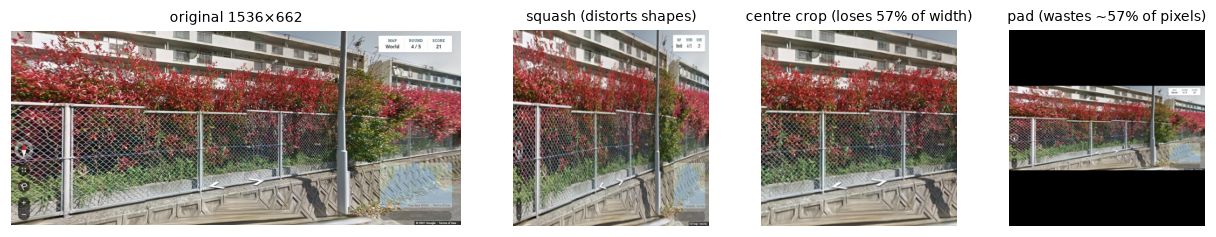

In [6]:
ex = Image.open(DATA_ROOT / manifest[manifest.country == "Japan"].path.iloc[3]).convert("RGB")
w, h = ex.size
squash = ex.resize((224, 224))
crop = ex.crop(((w - h) // 2, 0, (w + h) // 2, h)).resize((224, 224))
pad = Image.new("RGB", (w, w)); pad.paste(ex, (0, (w - h) // 2)); pad = pad.resize((224, 224))
fig, axs = plt.subplots(1, 4, figsize=(14, 3.2), gridspec_kw={"width_ratios": [2.3, 1, 1, 1]})
for a, im, t in zip(axs, [ex, squash, crop, pad],
                    ["original 1536×662", "squash (distorts shapes)",
                     f"centre crop (loses {1 - h / w:.0%} of width)", "pad (wastes ~57% of pixels)"]):
    a.imshow(im); a.set_title(t, fontsize=9); a.axis("off")
save(fig, "03_resize_options.png"); plt.show()

None of the options is free:
- **Squash** keeps everything but stretches shapes vertically. CNNs cope reasonably well with this, and it's the cheapest.
- **Centre crop** keeps shapes but throws away **57% of the image**, including the sides of the road where signs and
  poles often are.
- **Pad** keeps everything undistorted but most of the 224×224 input is black, so real detail drops to ~224×97 px.

*Recommendation:* train with **squash**, and compare against a wider non-square input (e.g. 224×448, which pretrained
CNNs accept) if time allows. Mohamed and Maya should decide, but whatever they pick must be the same for every model.

## 4. What the images look like

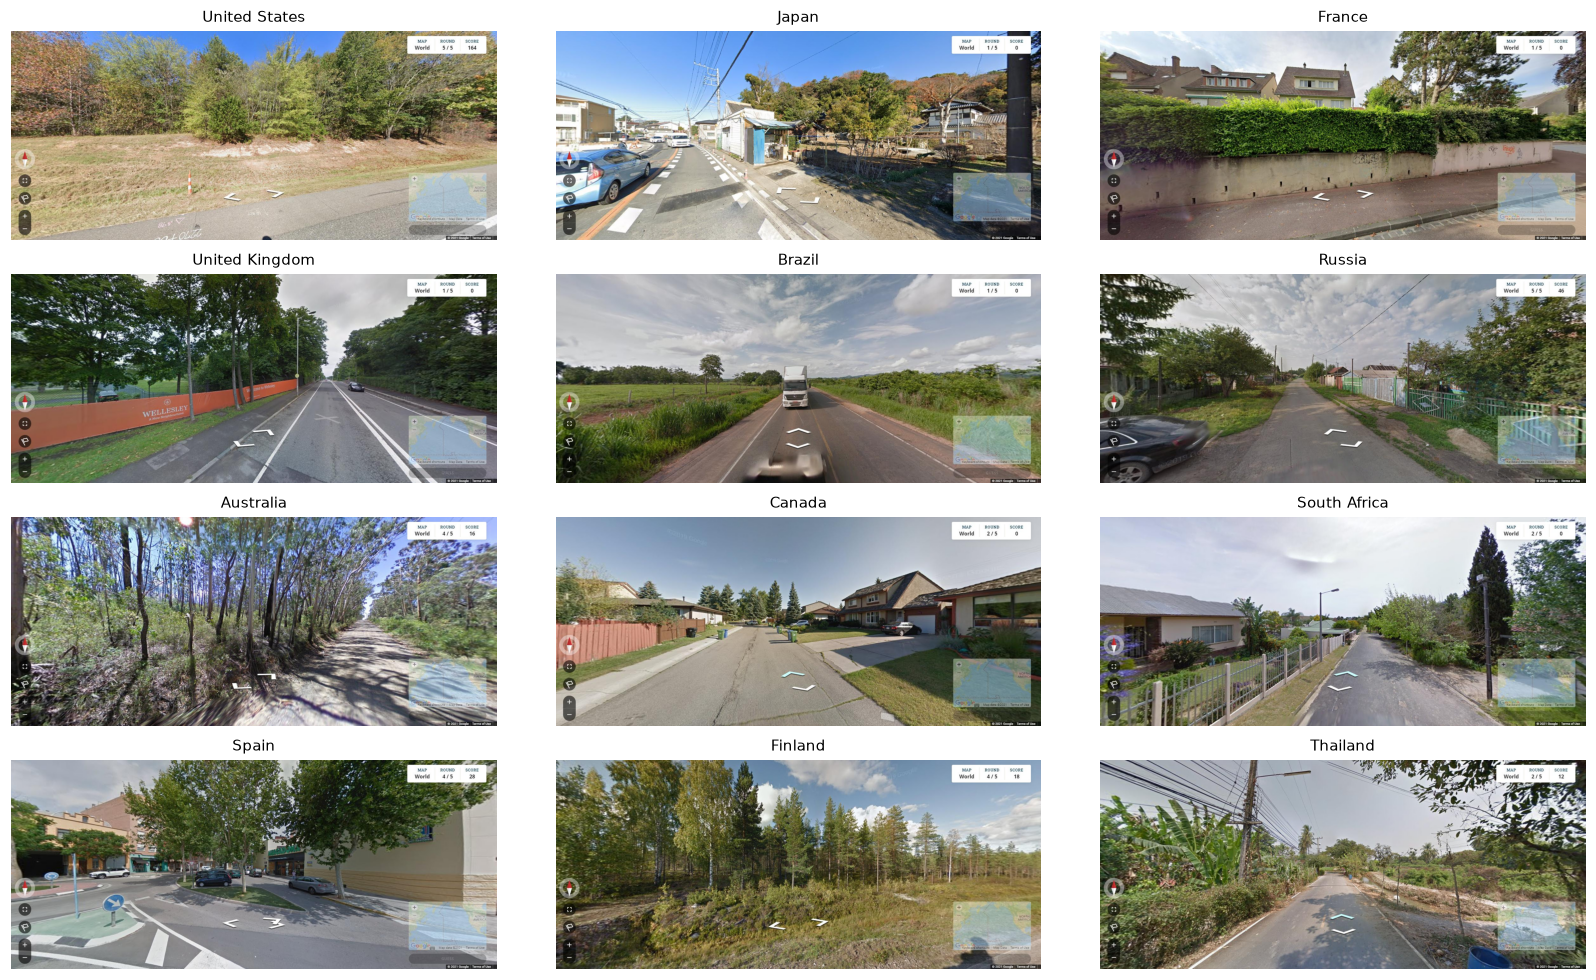

In [7]:
show = kept.index[:12]
fig, axs = plt.subplots(4, 3, figsize=(15, 9))
for a, c in zip(axs.flat, show):
    p = manifest[manifest.country == c].sample(1, random_state=1).path.iloc[0]
    a.imshow(Image.open(DATA_ROOT / p)); a.set_title(c, fontsize=10); a.axis("off")
plt.tight_layout(); save(fig, "04_sample_grid.png"); plt.show()

## 5. The GeoGuessr interface is on every image
Screenshots include the game interface: score box, compass, zoom buttons, minimap. To find where it is, we average
~1,500 random images pixel by pixel. Real scenery changes from image to image, but the interface is always in the same
place, so its pixels have **almost no variation** (low standard deviation).

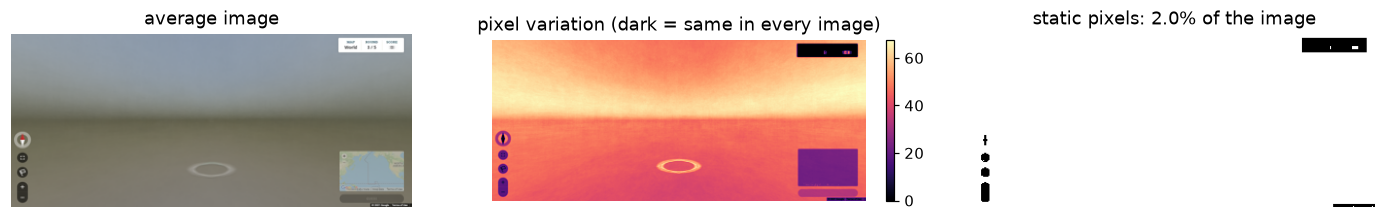

In [8]:
sample = manifest.sample(1500, random_state=0).path
SMALL = (384, 166)
acc = np.zeros((SMALL[1], SMALL[0], 3)); acc2 = np.zeros_like(acc)
for p in sample:
    im = Image.open(DATA_ROOT / p); im.draft("RGB", SMALL)
    a = np.asarray(im.convert("RGB").resize(SMALL), dtype=np.float64)
    acc += a; acc2 += a ** 2
mean = acc / len(sample); std = np.sqrt(np.maximum(acc2 / len(sample) - mean ** 2, 0)).mean(axis=2)
static = std < 20                                     # pixels that barely change = interface
fig, axs = plt.subplots(1, 3, figsize=(16, 3.2))
axs[0].imshow(mean.astype(np.uint8)); axs[0].set_title("average image")
im1 = axs[1].imshow(std, cmap="magma"); axs[1].set_title("pixel variation (dark = same in every image)")
plt.colorbar(im1, ax=axs[1], fraction=0.02)
axs[2].imshow(static, cmap="gray_r"); axs[2].set_title(f"static pixels: {static.mean():.1%} of the image")
for a in axs: a.axis("off")
save(fig, "05_interface_overlay.png"); plt.show()

What the variation map shows:
- **Score box (top-right) and compass/zoom buttons (left)** are identical in every image (dark = no variation).
  A **fixed mask** over these boxes is valid; no per-image detection is needed.
- **Minimap (bottom-right)** is semi-transparent, so the street shows through and it varies a little. It's still always
  in the same box, so mask the whole rectangle.
- **Navigation arrows (bright ring in the middle of the road)** point in a different direction in every image, so they
  **cannot** be removed with a fixed mask. They appear on every image, so they don't reveal the country, but they cover
  part of the road surface, which is a real cue (road markings).

Why it matters: the interface carries **no country information**. If Faris's Grad-CAM shows the model looking at the
score box or minimap, that's a red flag.

## 6. Colour by country

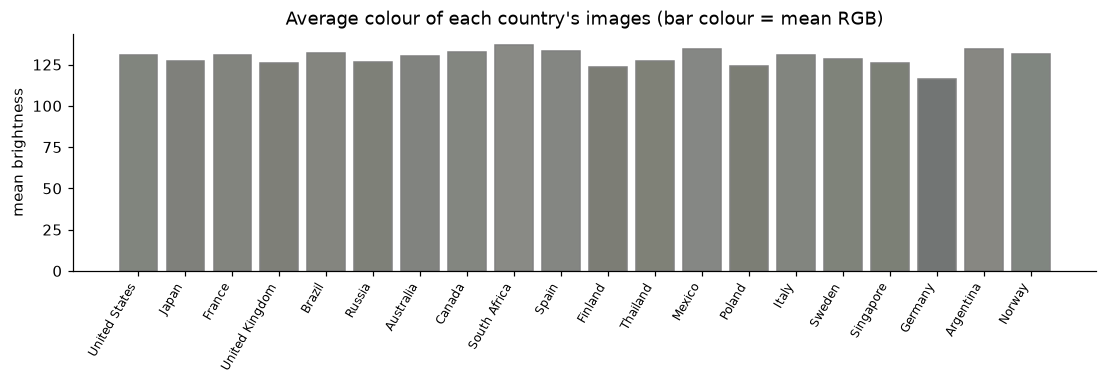

In [9]:
s = stats.merge(manifest[["path", "split"]], on="path")
top = kept.index[:20]
col = s[s.country.isin(top)].groupby("country")[["mean_r", "mean_g", "mean_b", "brightness"]].mean().loc[top]
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.bar(range(len(col)), col.brightness, color=(col[["mean_r", "mean_g", "mean_b"]] / 255).values, edgecolor="grey")
ax.set_xticks(range(len(col)), col.index, rotation=60, ha="right", fontsize=8)
ax.set_ylabel("mean brightness"); ax.set_title("Average colour of each country's images (bar colour = mean RGB)")
save(fig, "06_colour_by_country.png"); plt.show()

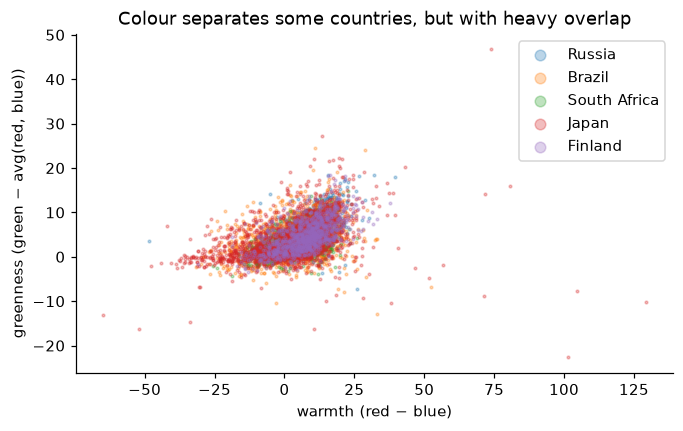

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
for c in ["Russia", "Brazil", "South Africa", "Japan", "Finland"]:
    d = s[s.country == c]
    ax.scatter(d.mean_r - d.mean_b, d.mean_g - (d.mean_r + d.mean_b) / 2, s=3, alpha=0.3, label=c)
ax.set_xlabel("warmth (red − blue)"); ax.set_ylabel("greenness (green − avg(red, blue))")
ax.legend(markerscale=4); ax.set_title("Colour separates some countries, but with heavy overlap")
save(fig, "07_colour_scatter.png"); plt.show()

Countries differ in overall colour (dry, warm red soil vs. green and grey), which is exactly the cue GeoGuessr players use.
But the clouds overlap heavily, so colour alone can't identify most countries. This is what Thea's colour-histogram
baseline will measure.

## 7. Shortcut check: can the model cheat?
A model can score well by learning something that **correlates with the country in this dataset** but isn't about the
place, for example camera quality or compression. Test: train a simple classifier on **non-visual metadata only**
(file size in bytes) and compare it with the majority-class baseline. If file size alone predicts the country well, the
images carry a technical fingerprint per country.

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
tr, va = s[s.split == "train"], s[s.split == "val"]
rows = [{"features": "majority class", "accuracy": (va.country == tr.country.mode()[0]).mean(),
         "macro-F1": f1_score(va.country, [tr.country.mode()[0]] * len(va), average="macro")}]
for name, feats in [("file size only", ["bytes"]),
                    ("colour stats only", ["mean_r", "mean_g", "mean_b", "brightness", "brightness_std"]),
                    ("file size + colour", ["bytes", "mean_r", "mean_g", "mean_b", "brightness", "brightness_std"])]:
    rf = RandomForestClassifier(300, min_samples_leaf=5, n_jobs=-1, random_state=0, class_weight="balanced")
    rf.fit(tr[feats], tr.country); pred = rf.predict(va[feats])
    rows.append({"features": name, "accuracy": accuracy_score(va.country, pred),
                 "macro-F1": f1_score(va.country, pred, average="macro")})
shortcut = pd.DataFrame(rows).round(3); shortcut

,features,accuracy,macro-F1
0,majority class,0.251,0.007
1,file size only,0.006,0.007
2,colour stats only,0.033,0.030
3,file size + colour,0.041,0.038


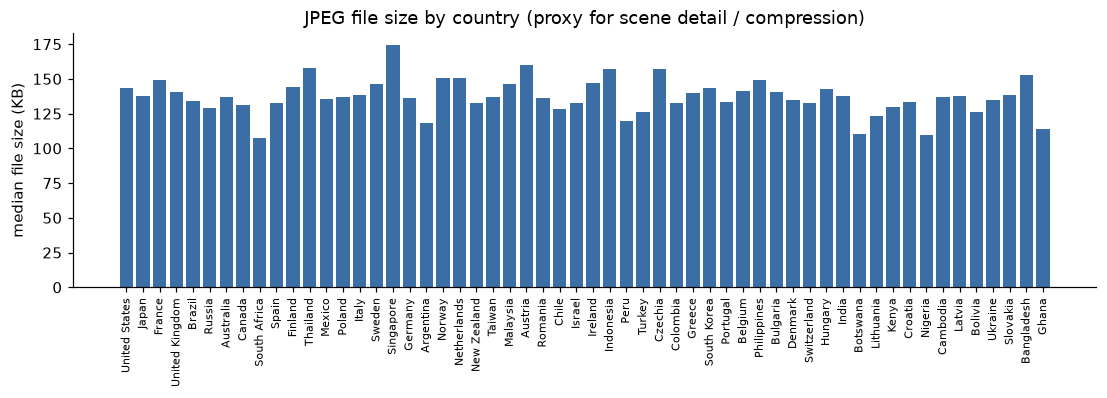

In [12]:
fs = s.groupby("country").bytes.median().loc[kept.index] / 1e3
fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(range(len(fs)), fs.values, color="#3b6ea5"); ax.set_xticks(range(len(fs)), fs.index, rotation=90, fontsize=7)
ax.set_ylabel("median file size (KB)"); ax.set_title("JPEG file size by country (proxy for scene detail / compression)")
save(fig, "08_filesize_by_country.png"); plt.show()

*How to read the table:* the random forests use balanced class weights, so their accuracy is **not** comparable to the
majority baseline (which wins on accuracy just by always saying USA). Compare **macro-F1** with random guessing
across 56 countries (1/56 ≈ 0.018):
- **File size only ≈ chance** → no technical fingerprint per country. The model can't cheat via compression or
  camera quality, which is good news.
- **Colour stats ≈ 2× chance** → colour is a real but weak signal, consistent with section 6. The CNN has to learn
  much more than colour.

## 8. Summary for the team

In [13]:
summary = f'''# EDA summary – GeoSense

- **Data:** {len(stats):,} raw images, {stats.country.nunique()} countries, all 1536x662 JPEG ({stats.bytes.sum()/1e9:.1f} GB).
  After cleaning: {len(manifest):,} images, {manifest.country.nunique()} countries (>= 100 images each).
- **Imbalance:** USA = {kept.iloc[0]:,} images ({kept.iloc[0]/kept.sum():.0%}); smallest = {kept.iloc[-1]}.
  Always guessing USA gives {kept.iloc[0]/kept.sum():.0%} accuracy -> report macro-F1, use class weights / weighted sampling.
- **Shape:** 2.3:1 panoramas. Centre-crop to square drops 57% of the width; recommend squash (or 224x448).
- **Interface overlay:** score box, buttons and minimap sit in fixed positions -> fixed mask is valid; navigation arrows move -> cannot be masked.
- **Colour:** differs by country but overlaps strongly; useful baseline feature, not sufficient alone.
- **Shortcut check (validation set, chance macro-F1 = 1/56 = 0.018):** file size alone is at chance (no technical fingerprint); colour is ~2x chance (weak real signal).

{shortcut.to_markdown(index=False)}

- **Limitation:** duplicate detection only catches identical screenshots; same place / other heading can still cross splits.
'''
(RESULTS / "eda_summary.md").write_text(summary); print(summary)

# EDA summary – GeoSense

- **Data:** 49,997 raw images, 124 countries, all 1536x662 JPEG (7.2 GB).
  After cleaning: 47,990 images, 56 countries (>= 100 images each).
- **Imbalance:** USA = 12,014 images (25%); smallest = 106.
  Always guessing USA gives 25% accuracy -> report macro-F1, use class weights / weighted sampling.
- **Shape:** 2.3:1 panoramas. Centre-crop to square drops 57% of the width; recommend squash (or 224x448).
- **Interface overlay:** score box, buttons and minimap sit in fixed positions -> fixed mask is valid; navigation arrows move -> cannot be masked.
- **Colour:** differs by country but overlaps strongly; useful baseline feature, not sufficient alone.
- **Shortcut check (validation set, chance macro-F1 = 1/56 = 0.018):** file size alone is at chance (no technical fingerprint); colour is ~2x chance (weak real signal).

| features           |   accuracy |   macro-F1 |
|:-------------------|-----------:|-----------:|
| majority class     |      0.251 |      0.007 